
# 2026 年全国大学生数学建模竞赛 A 题  
# 第三问最终竞赛版：结果生成、科研绘图与论文配图 Notebook

本 Notebook 面向第三问的最终论文撰写与结果整理，基于你上传的项目代码 `q2_solver.py` 与 `q3_solver.py` 编写，包含以下内容：

1. **附件 1 环境温度数据**：散点图 + 线性插值图（全部数据点）  
2. **附件 1 环境水分浓度数据**：散点图 + 线性插值图（全部数据点）  
3. **第三问生产级求解**：采用上传代码的求解框架，使用 **N = 1280** 生成 `result3.xlsx`  
4. **表 5 导出**：生成第三问关键时刻的 `csv` 表格  
5. **温度 / 水分浓度热力图**：横轴为时间，纵轴为距圆心距离  
6. **温度 / 水分浓度随距离变化图**：典型时刻下的径向剖面  
7. **热力图 + 临界等值线**：以及推荐正文图 `Fig1 ~ Fig6` 的自动导出  
8. **可选的高分论文附加分析**：局部达标时间、网格收敛、边界敏感性等

---

## 论文写作提醒

- 本 Notebook 中所有图题、坐标轴和图例均使用**中文**，便于你直接核对内容。  
- 所有数据均来自**真实数值计算结果**，不进行手工平滑、虚构或人为修饰。  
- 坐标轴尽量按题目语境命名，例如：  
  - 时间 / h  
  - 距圆心距离 / cm  
  - 温度 / ℃  
  - 水分浓度 / (kg/kg)  
- 最终论文正文可保留中文图题，也可在定稿前统一改为英文图内文字；本 Notebook 以**当前你的要求：中文版本**为准。  


> **绘图版式约定：所有生成图片均不在图内添加标题，图题统一放在论文正文或图注中。**

In [4]:
# =========================
# Cell 1：环境准备与路径配置
# =========================

from pathlib import Path
import sys
import os
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager

warnings.filterwarnings("ignore")


# ============================================================
# 1. 自动识别项目根目录
# ============================================================
# 推荐目录结构：
#
# Q3_drying_project/
# ├── data/
# │   └── 附件1.xlsx
# ├── docs/
# ├── notebooks/
# ├── outputs/
# ├── src/
# │   ├── q2_solver.py
# │   └── q3_solver.py
# ├── validation/
# └── Q3_第三问最终竞赛版_无图片标题.ipynb
#
# 当前 Notebook 位于项目根目录时：
# Path.cwd() 即 Q3_drying_project

CURRENT_DIR = Path.cwd().resolve()


def is_q3_project_root(path: Path) -> bool:
    """判断给定路径是否为 Q3 项目根目录。"""
    return (
        (path / "src" / "q2_solver.py").exists()
        and (path / "src" / "q3_solver.py").exists()
        and (path / "data" / "附件1.xlsx").exists()
    )


# 优先从当前工作目录识别
candidate_roots = [
    CURRENT_DIR,
    CURRENT_DIR.parent,
]

PROJECT_DIR = None

for root in candidate_roots:
    if is_q3_project_root(root):
        PROJECT_DIR = root.resolve()
        break


# 若仍未找到，则向上逐级搜索
if PROJECT_DIR is None:
    for parent in [CURRENT_DIR, *CURRENT_DIR.parents]:
        if is_q3_project_root(parent):
            PROJECT_DIR = parent.resolve()
            break


# 找不到则明确报错
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "无法定位 Q3_drying_project 项目根目录。\n"
        f"当前工作目录为：{CURRENT_DIR}\n\n"
        "请确认项目目录中至少存在：\n"
        "  src/q2_solver.py\n"
        "  src/q3_solver.py\n"
        "  data/附件1.xlsx\n"
    )


# ============================================================
# 2. 设置 Python 模块搜索路径
# ============================================================

SRC_DIR = PROJECT_DIR / "src"

# 确保优先导入当前项目中的 q2_solver / q3_solver
src_str = str(SRC_DIR)

if src_str in sys.path:
    sys.path.remove(src_str)

sys.path.insert(0, src_str)


# ============================================================
# 3. 数据路径
# ============================================================

ENV_XLSX = PROJECT_DIR / "data" / "附件1.xlsx"


# ============================================================
# 4. 输出目录
# ============================================================

OUTPUT_DIR = PROJECT_DIR / "Q3_第三问最终竞赛版输出"
IMG_DIR = OUTPUT_DIR / "images"
TAB_DIR = OUTPUT_DIR / "tables"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 5. 导入第三问项目代码
# ============================================================

from q3_solver import (
    LongTermEnvironment,
    Q3SolverConfig,
    solve_q3,
    write_result3,
    paper_table5,
    drying_event_summary,
    environment_summary,
    cmax_location_history,
    physical_diagnostics_q3,
    event_local_trace,
    event_grid_convergence,
    boundary_strategy_sensitivity,
    sample_state_pair,
)


# ============================================================
# 6. 中文字体设置，避免乱码
# ============================================================

candidate_fonts = [
    "Noto Sans CJK SC",
    "Source Han Sans SC",
    "Microsoft YaHei",
    "SimHei",
    "WenQuanYi Zen Hei",
    "PingFang SC",
    "Heiti SC",
    "STHeiti",
    "Arial Unicode MS",
    "DejaVu Sans",
]

available_fonts = {f.name for f in font_manager.fontManager.ttflist}

selected_font = next(
    (font for font in candidate_fonts if font in available_fonts),
    None
)

if selected_font is not None:
    mpl.rcParams["font.sans-serif"] = [selected_font]
else:
    mpl.rcParams["font.sans-serif"] = ["DejaVu Sans"]

# 解决负号显示异常
mpl.rcParams["axes.unicode_minus"] = False

# 绘图分辨率
mpl.rcParams["figure.dpi"] = 120
mpl.rcParams["savefig.dpi"] = 300


# ============================================================
# 7. 公共保存函数
# ============================================================

def 保存图片(fig, filename: str):
    """
    保存 PNG 科研图片。
    注意：图片标题由各绘图 Cell 控制；
    当前最终版 Notebook 已取消图内标题。
    """
    path = IMG_DIR / filename
    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )
    print(f"已保存图片：{path}")
    return path


def 保存表格(
    df: pd.DataFrame,
    filename: str,
    index=True,
    encoding="utf-8-sig"
):
    """
    保存 CSV。
    utf-8-sig 可提高 Windows Excel 对中文的兼容性。
    """
    path = TAB_DIR / filename
    df.to_csv(
        path,
        index=index,
        encoding=encoding
    )
    print(f"已保存表格：{path}")
    return path


def 保存Excel(
    df: pd.DataFrame,
    filename: str,
    index=True
):
    """保存 Excel 表格。"""
    path = TAB_DIR / filename
    df.to_excel(
        path,
        index=index
    )
    print(f"已保存 Excel：{path}")
    return path


# ============================================================
# 8. 路径和模块自检
# ============================================================

print("=" * 70)
print("Q3 Notebook 环境与路径自检")
print("=" * 70)

print(f"当前工作目录：\n{CURRENT_DIR}\n")

print(f"识别到的项目根目录：\n{PROJECT_DIR}\n")

print(f"src 目录：\n{SRC_DIR}")
print(
    "q2_solver.py：",
    "存在" if (SRC_DIR / "q2_solver.py").exists() else "不存在"
)
print(
    "q3_solver.py：",
    "存在" if (SRC_DIR / "q3_solver.py").exists() else "不存在"
)

print()

print(f"附件1路径：\n{ENV_XLSX}")
print(
    "附件1.xlsx：",
    "存在" if ENV_XLSX.exists() else "不存在"
)

print()

print(f"结果输出目录：\n{OUTPUT_DIR}")
print(f"图片输出目录：\n{IMG_DIR}")
print(f"表格输出目录：\n{TAB_DIR}")

print()

print(f"当前绘图字体：{mpl.rcParams['font.sans-serif'][0]}")

print()
print("q3_solver 导入成功。")

print("=" * 70)


Q3 Notebook 环境与路径自检
当前工作目录：
/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project

识别到的项目根目录：
/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project

src 目录：
/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/src
q2_solver.py： 存在
q3_solver.py： 存在

附件1路径：
/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/data/附件1.xlsx
附件1.xlsx： 存在

结果输出目录：
/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出
图片输出目录：
/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images
表格输出目录：
/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables

当前绘图字体：Noto Sans CJK SC

q3_solver 导入成功。



## 第一部分：读取附件 1 数据

本部分对应论文中“边界条件数据说明”。  
我们先读取附件 1 中给出的环境温度与环境水分浓度数据，并进行可视化。

### 论文写作提示
这一部分的作用不是展示算法结果，而是**解释第三问的外部边界输入**。  
正文可强调：

- 附件 1 给出了前 4 小时的环境数据；
- 在 0–4 h 内，边界采用**原始数据点 + 线性插值**；
- 后续长期计算可基于末段平台做延拓（在后文求解部分给出）。

这两张图非常适合作为“数据预处理与边界构造”的配图。


In [5]:

# =========================
# 1. 读取附件 1 数据
# =========================
env_df = pd.read_excel(ENV_XLSX)
env_df = env_df[["时间", "温度", "水分浓度"]].copy()
env_df = env_df.sort_values("时间").reset_index(drop=True)

# 增加小时列，便于绘图
env_df["时间_h"] = env_df["时间"] / 3600.0

# 保存原始数据为 csv，便于论文整理
保存表格(env_df, "附件1环境数据_原始整理.csv", index=False)

env_df.head()

已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/附件1环境数据_原始整理.csv


,时间,温度,水分浓度,时间_h
0,0,28.000,0.01963,0.000000
1,60,28.528,0.02002,0.016667
2,120,29.192,0.02053,0.033333
3,180,29.684,0.02100,0.050000
4,240,30.037,0.02151,0.066667



## 第二部分：环境温度散点图与线性插值图（全部数据点）

### 论文写作提示
可在正文中写成：

> 附件 1 给出了环境温度随时间的离散观测值。为保证数值求解过程中边界条件在任意时刻可调用，本文对相邻采样点之间采用线性插值，从而构造连续的环境温度边界函数。

若你的正文篇幅有限，可以把本图与下一张“环境水分浓度图”合并成一个双子图作为正文 Fig.1。


已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/图1_环境温度散点与线性插值.png


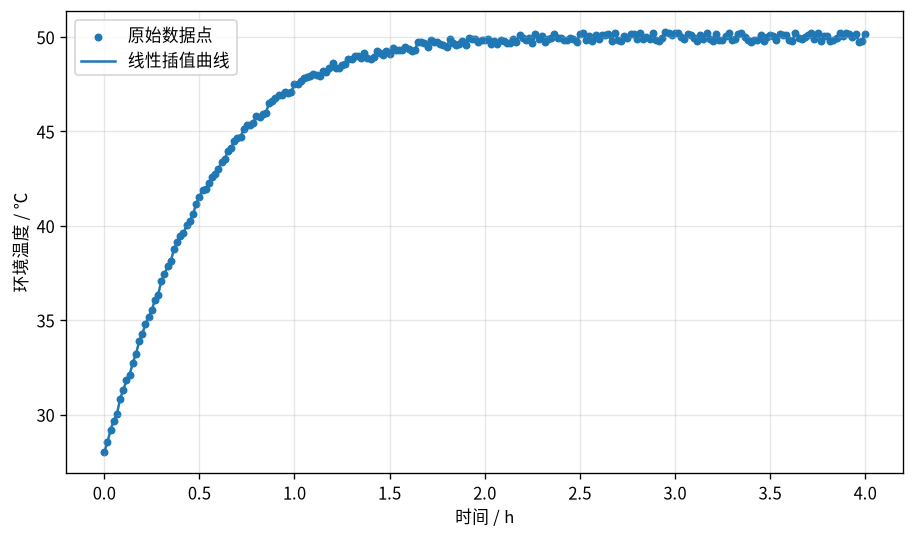

In [6]:

# =========================
# 2. 环境温度：散点图 + 线性插值图（全部数据点）
# =========================
t_raw_h = env_df["时间_h"].to_numpy()
T_raw = env_df["温度"].to_numpy()

t_dense_h = np.linspace(t_raw_h.min(), t_raw_h.max(), len(t_raw_h) * 20)
T_dense = np.interp(t_dense_h, t_raw_h, T_raw)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(t_raw_h, T_raw, s=14, label="原始数据点")
ax.plot(t_dense_h, T_dense, label="线性插值曲线")

ax.set_xlabel("时间 / h")
ax.set_ylabel("环境温度 / ℃")
ax.grid(True, alpha=0.3)
ax.legend()

保存图片(fig, "图1_环境温度散点与线性插值.png")
plt.show()


## 第三部分：环境水分浓度散点图与线性插值图（全部数据点）

### 论文写作提示
可在正文中写成：

> 附件 1 同时给出了环境水分浓度数据。本文同样采用线性插值构造连续边界函数，使其能够在数值积分过程中与环境温度边界同步调用。

在论文表达上，建议统一使用“**水分浓度**”这一术语，与模型中的变量 \(C\) 保持一致。  
如果你更想从题面语言出发，也可以在图题中写成“环境湿度（水分浓度）”。


已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/图2_环境水分浓度散点与线性插值.png


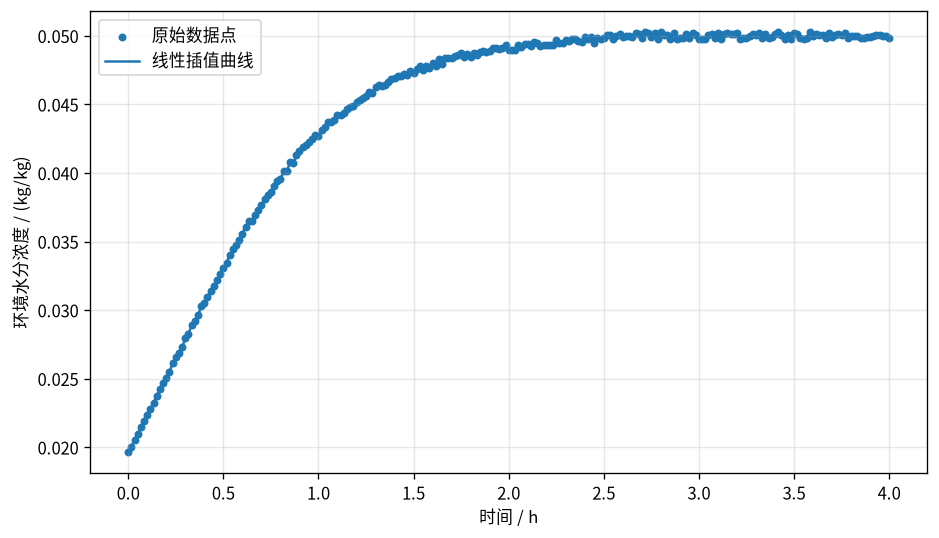

In [7]:

# =========================
# 3. 环境水分浓度：散点图 + 线性插值图（全部数据点）
# =========================
Cinf_raw = env_df["水分浓度"].to_numpy()
Cinf_dense = np.interp(t_dense_h, t_raw_h, Cinf_raw)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(t_raw_h, Cinf_raw, s=14, label="原始数据点")
ax.plot(t_dense_h, Cinf_dense, label="线性插值曲线")

ax.set_xlabel("时间 / h")
ax.set_ylabel("环境水分浓度 / (kg/kg)")
ax.grid(True, alpha=0.3)
ax.legend()

保存图片(fig, "图2_环境水分浓度散点与线性插值.png")
plt.show()


## 第四部分：构造长期边界，并生成推荐正文 Fig.1

第三问要求预测总干燥时间，计算时间远超过附件给出的 4 小时观测窗口。  
根据你当前上传代码的默认做法，这里采用：

- **0–4 h**：使用原始数据点的线性插值；
- **4 h 之后**：采用末 1 小时均值作为平台延拓（`last_hour_mean`）。

### 论文写作提示
这张图很适合放在正文中作为 **Fig.1**，说明第三问的边界条件构造逻辑。  
图中建议让评委一眼看到：

- 前 4 小时是实测数据；
- 4 小时之后边界保持平台稳定；
- 长期预测并不是“随意外推”，而是基于末段数据平台的统计延拓。


已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/第三问长期边界统计量.csv
已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/推荐Fig1_环境边界条件及长期延拓.png


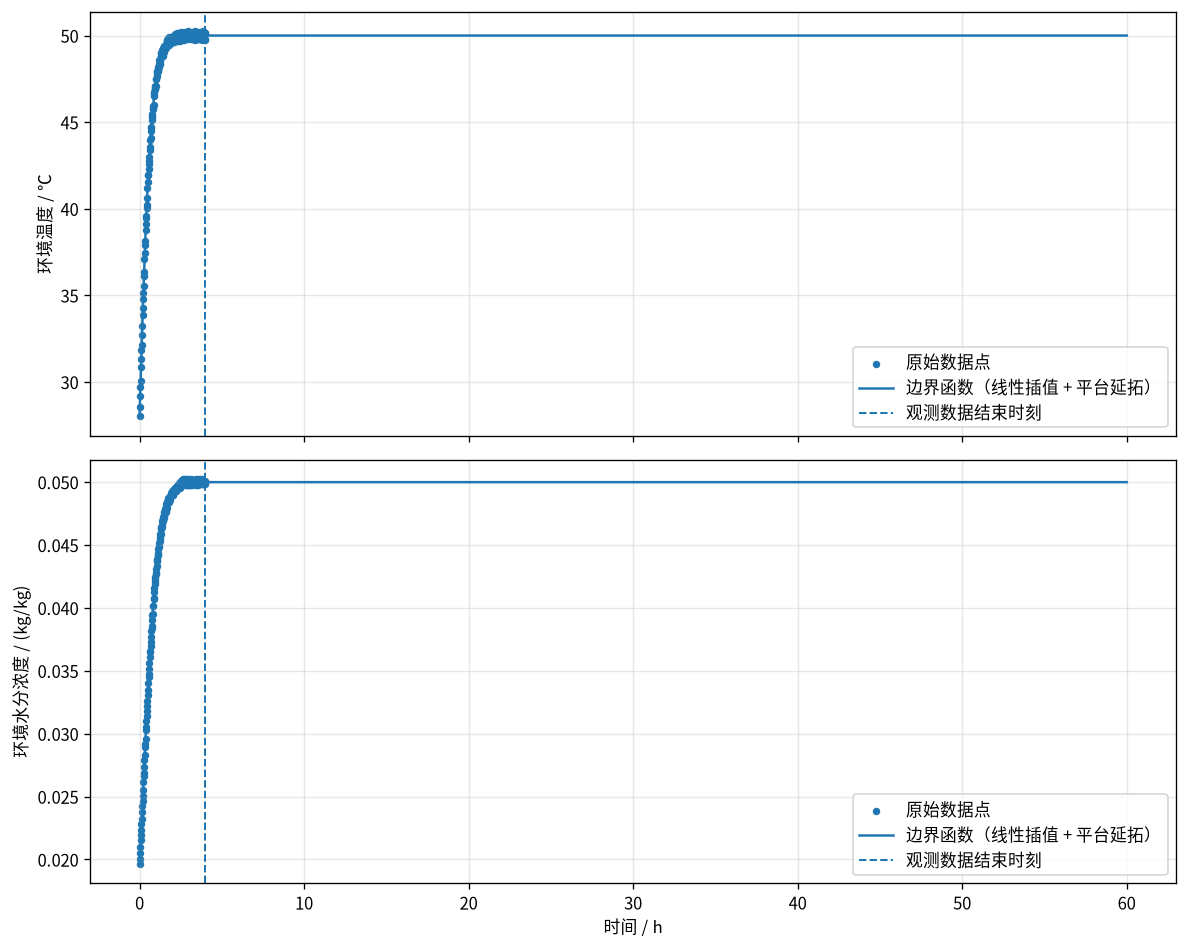

,strategy,data_end_h,window_start_h,window_end_h,n_points,T_long_C,T_std_C,T_slope_C_per_h,C_long,C_std,C_slope_per_h
0,last_hour_mean,4.0,3.0,4.0,61,49.998934,0.154353,0.002824,0.049988,0.00015,-0.000013


In [8]:

# =========================
# 4. 长期边界延拓 + 推荐 Fig.1
# =========================
env_long = LongTermEnvironment.from_excel(ENV_XLSX, strategy="last_hour_mean")
env_summary_df = environment_summary(env_long)
保存表格(env_summary_df, "第三问长期边界统计量.csv", index=False)

t_end_h = env_long.data_end_s / 3600.0
t_pred_h = 60.0  # 为了展示延拓，先画到 60 h
t_long_h = np.linspace(0.0, t_pred_h, 3000)
t_long_s = t_long_h * 3600.0

T_long = env_long.T_inf(t_long_s)
C_long = env_long.C_inf(t_long_s)

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# 上图：环境温度
axes[0].scatter(t_raw_h, T_raw, s=12, label="原始数据点")
axes[0].plot(t_long_h, T_long, label="边界函数（线性插值 + 平台延拓）")
axes[0].axvline(t_end_h, linestyle="--", linewidth=1.2, label="观测数据结束时刻")
axes[0].set_ylabel("环境温度 / ℃")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# 下图：环境水分浓度
axes[1].scatter(t_raw_h, Cinf_raw, s=12, label="原始数据点")
axes[1].plot(t_long_h, C_long, label="边界函数（线性插值 + 平台延拓）")
axes[1].axvline(t_end_h, linestyle="--", linewidth=1.2, label="观测数据结束时刻")
axes[1].set_xlabel("时间 / h")
axes[1].set_ylabel("环境水分浓度 / (kg/kg)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()

保存图片(fig, "推荐Fig1_环境边界条件及长期延拓.png")
plt.show()

env_summary_df


## 第五部分：第三问生产级求解，并生成 `result3.xlsx` 与表 5

这里直接调用你上传项目中的 `solve_q3` 与 `write_result3`。  
计算设置遵循当前第三问代码框架，并将空间网格设为：

\[
N = 1280
\]

### 论文写作提示
本部分在论文中需要说明三点：

1. 第三问沿用第二问的热—湿耦合模型；
2. 传热与传质系数沿用问题一标定结果；
3. 采用圆柱坐标有限体积离散 + BDF 时间积分，在全域范围内判定
   \[
   \max_r C(r,t)\le 0.15
   \]
   的首次时刻，即为干燥完成时间。

> **注意**：以下代码如果真正运行，N=1280 属于正式生产级求解，运行时间会明显高于烟雾测试。


In [9]:

# =========================
# 5. 第三问生产级求解（N = 1280）
# =========================

# 若你只想先调试 Notebook 结构，可把 RUN_PRODUCTION 改为 False，
# 然后手工加载已有结果；用于论文定稿时请保持 True。
RUN_PRODUCTION = True

# 生产级求解配置
q3_config = Q3SolverConfig(
    rtol=1.0e-9,
    atol=1.0e-11,
    max_step_data=5.0,
    max_step_long=60.0,
    output_dt=60.0,
    output_dr=0.001,   # 0.1 cm
    refine_event=True,
    event_rtol=2.0e-10,
    event_atol=2.0e-12,
    event_max_step=5.0,
    max_time_s=15.0 * 24.0 * 3600.0,
)

if RUN_PRODUCTION:
    sol = solve_q3(
        env_path=ENV_XLSX,
        N=1280,
        config=q3_config,
        boundary_strategy="last_hour_mean",
    )

    # 保存官方结果文件
    result3_path = OUTPUT_DIR / "result3.xlsx"
    write_result3(sol, result3_path)

    # 兼容性：另存一个带 N 标识的文件
    result3_n_path = OUTPUT_DIR / "result3_N1280.xlsx"
    write_result3(sol, result3_n_path)

    # 保存表 5
    table5_df = paper_table5(sol).copy()
    table5_df.index.name = "时间 / h"
    table5_df.columns.name = "距圆心距离 / cm"
    保存表格(table5_df, "表5_第三问关键时刻水分浓度.csv", index=True)
    保存Excel(table5_df, "表5_第三问关键时刻水分浓度.xlsx", index=True)

    # 保存辅助汇总表
    event_summary_df = pd.DataFrame([drying_event_summary(sol)])
    phys_diag_df = pd.DataFrame([physical_diagnostics_q3(sol)])
    stats_df = pd.DataFrame([sol.solver_stats])

    保存表格(event_summary_df, "第三问终止事件汇总.csv", index=False)
    保存表格(phys_diag_df, "第三问物理诊断汇总.csv", index=False)
    保存表格(stats_df, "第三问求解器统计.csv", index=False)

    # 保存规则输出的温度场、水分场矩阵
    T_matrix_df = pd.DataFrame(sol.T, index=sol.t, columns=np.round(sol.r * 100.0, 4))
    C_matrix_df = pd.DataFrame(sol.C, index=sol.t, columns=np.round(sol.r * 100.0, 4))
    T_matrix_df.index.name = "时间 / s"
    C_matrix_df.index.name = "时间 / s"
    T_matrix_df.columns.name = "距圆心距离 / cm"
    C_matrix_df.columns.name = "距圆心距离 / cm"

    保存表格(T_matrix_df, "规则输出_温度场矩阵.csv", index=True)
    保存表格(C_matrix_df, "规则输出_水分场矩阵.csv", index=True)

    print("\n===== 第三问关键结果 =====")
    print(f"干燥完成时刻：{sol.t_dry_s:.6f} s = {sol.t_dry_s / 3600.0:.6f} h")
    print(f"终止时最大水分浓度：{sol.Cmax_dry:.6f}")
    print(f"终止控制位置：{sol.rmax_dry_m * 100.0:.4f} cm")
else:
    raise RuntimeError("当前 Notebook 未执行生产求解，请将 RUN_PRODUCTION 改为 True。")

已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/表5_第三问关键时刻水分浓度.csv
已保存 Excel：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/表5_第三问关键时刻水分浓度.xlsx
已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/第三问终止事件汇总.csv
已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/第三问物理诊断汇总.csv
已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/第三问求解器统计.csv
已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/规则输出_温度场矩阵.csv
已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/规则输出_水分场矩阵.csv

===== 第三问关键结果 =====
干燥完成时刻：206946.910964 s = 57.485253 h
终止时最大水分浓度：0.150000
终止控制位置：0.0000 cm



## 第六部分：表 5 预览

### 论文写作提示
表 5 可以直接作为正文或附录表格使用，用来展示典型时刻和烘干结束时刻下，不同径向位置的水分浓度。  
这张表的价值在于：

- 让评委直观看到内部与表面的差异；
- 显示末期干燥受中心区域控制；
- 支撑“各处水分浓度均不高于 0.15”这一最终结论。


In [10]:

# =========================
# 6. 表 5 预览
# =========================
table5_df

距圆心距离 / cm,0,0.5,1.0,1.5,2.0
时间 / h,,,,,
6,1.016968,0.988138,0.901527,0.755008,0.532779
12,0.456149,0.443165,0.403077,0.329739,0.164175
18,0.298843,0.291553,0.268713,0.225305,0.084457
24,0.237803,0.232743,0.216731,0.185562,0.066453
30,0.205830,0.201852,0.189177,0.164110,0.059824
36,0.185886,0.182539,0.171824,0.150396,0.056635
42,0.172076,0.169144,0.159721,0.140725,0.054841
48,0.161839,0.159200,0.150700,0.133453,0.053724
54,0.153879,0.151461,0.143656,0.127734,0.052975



## 第七部分：温度、湿度（即水分浓度）变化的热力图

下面绘制时间—距离二维热力图：

- 横轴：时间 / h
- 纵轴：距圆心距离 / cm
- 颜色：温度或水分浓度

### 论文写作提示
热力图非常适合展示“干燥前沿”如何随时间向内部推进。  
正文中可突出：

- 温度场较快趋于稳定；
- 水分浓度场变化更慢；
- 后期主要是内部水分迁移控制干燥过程。


已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/图3_温度场时空热力图.png
已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/推荐Fig2_温度场时空热力图.png


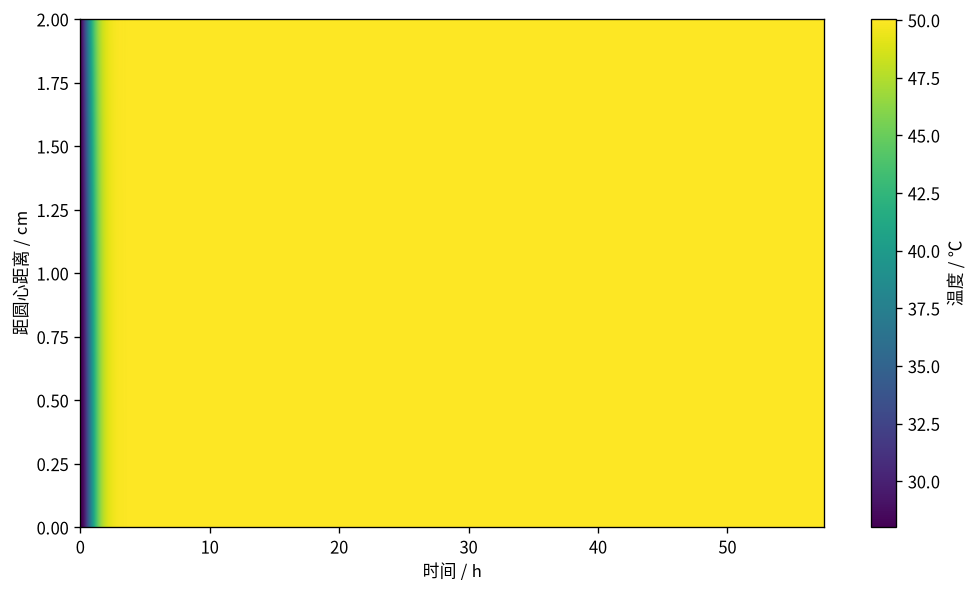

In [11]:

# =========================
# 7. 温度热力图
# =========================
time_h = sol.t / 3600.0
radius_cm = sol.r * 100.0

fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(
    sol.T.T,
    aspect="auto",
    origin="lower",
    extent=[time_h.min(), time_h.max(), radius_cm.min(), radius_cm.max()],
)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("温度 / ℃")

ax.set_xlabel("时间 / h")
ax.set_ylabel("距圆心距离 / cm")

保存图片(fig, "图3_温度场时空热力图.png")
保存图片(fig, "推荐Fig2_温度场时空热力图.png")
plt.show()

已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/图4_水分浓度场时空热力图.png
已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/推荐Fig3_水分浓度场时空热力图.png


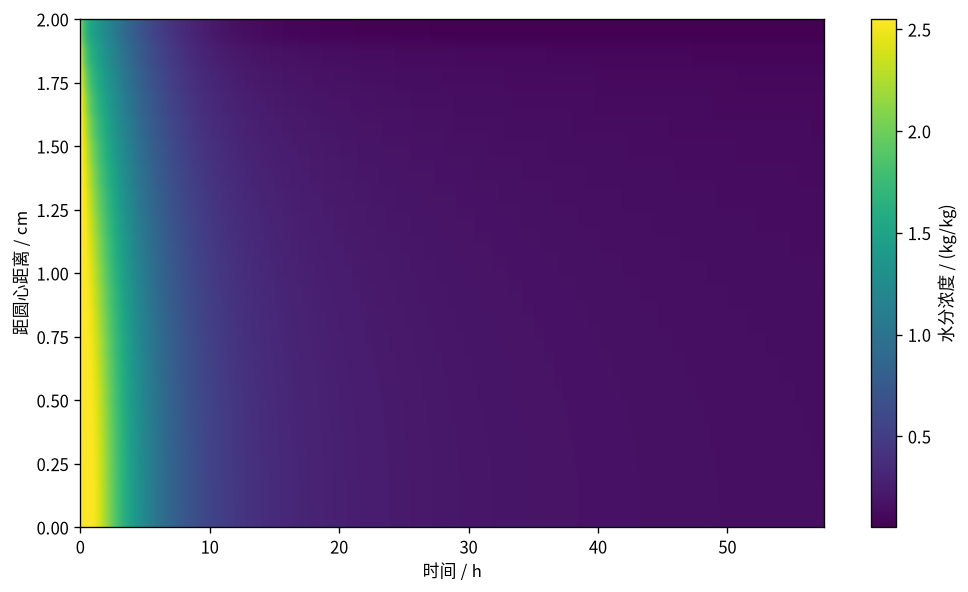

In [12]:

# =========================
# 8. 水分浓度热力图
# =========================
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(
    sol.C.T,
    aspect="auto",
    origin="lower",
    extent=[time_h.min(), time_h.max(), radius_cm.min(), radius_cm.max()],
)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("水分浓度 / (kg/kg)")

ax.set_xlabel("时间 / h")
ax.set_ylabel("距圆心距离 / cm")

保存图片(fig, "图4_水分浓度场时空热力图.png")
保存图片(fig, "推荐Fig3_水分浓度场时空热力图.png")
plt.show()


## 第八部分：温度 / 水分浓度随距离变化图（典型时刻径向剖面）

这部分用于展示典型时刻下，材料内部从中心到表面的分布状态。  
一般建议选取若干具有代表性的时刻，例如：

- 初始时刻
- 中前期：6 h、12 h、24 h
- 中后期：36 h、48 h、54 h
- 最后一个规则输出时刻

### 论文写作提示
这一组图适合用来强调：

- 温度梯度相对较快减弱；
- 水分浓度梯度持续存在；
- 接近结束时，表面已接近环境平衡，但中心仍接近阈值。


In [13]:

# =========================
# 9. 典型时刻选择
# =========================
candidate_hours = [0, 6, 12, 24, 36, 48, 54]
last_regular_h = sol.t[-1] / 3600.0
if last_regular_h not in candidate_hours:
    candidate_hours.append(round(last_regular_h, 3))

# 只保留可用时刻
profile_hours = []
for h in candidate_hours:
    if h <= last_regular_h + 1e-9:
        profile_hours.append(h)

# 去重并排序
profile_hours = sorted(set(profile_hours))

profile_indices = []
for h in profile_hours:
    target_s = h * 3600.0
    idx = int(np.argmin(np.abs(sol.t - target_s)))
    profile_indices.append(idx)

profile_hours_actual = [sol.t[idx] / 3600.0 for idx in profile_indices]
profile_hours_actual

[np.float64(0.0),
 np.float64(6.0),
 np.float64(12.0),
 np.float64(24.0),
 np.float64(36.0),
 np.float64(48.0),
 np.float64(54.0),
 np.float64(57.483333333333334)]

已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/图5_典型时刻温度随距离变化图.png


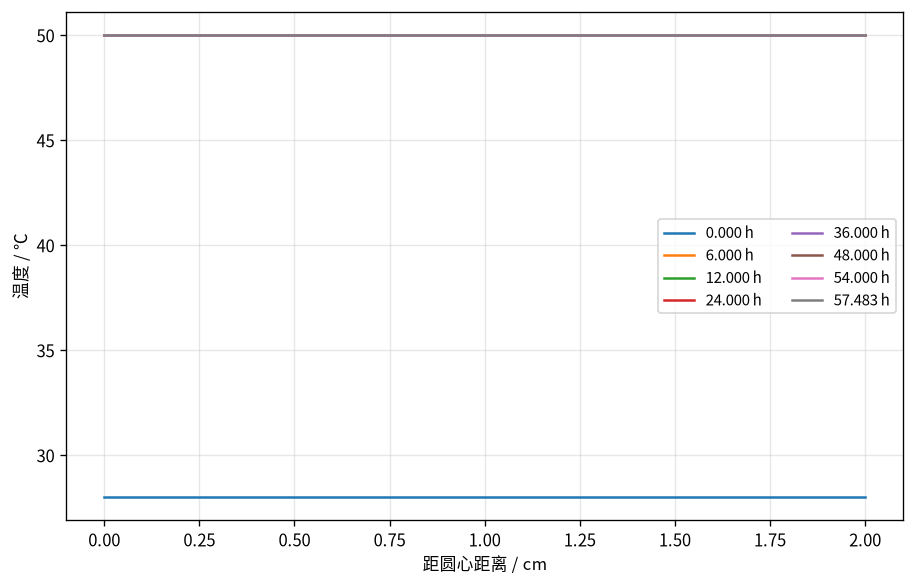

In [14]:

# =========================
# 10. 温度随距离变化图
# =========================
fig, ax = plt.subplots(figsize=(9, 5.5))

for idx, h in zip(profile_indices, profile_hours_actual):
    ax.plot(radius_cm, sol.T[idx, :], label=f"{h:.3f} h")

ax.set_xlabel("距圆心距离 / cm")
ax.set_ylabel("温度 / ℃")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=9)

保存图片(fig, "图5_典型时刻温度随距离变化图.png")
plt.show()

已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/图6_典型时刻水分浓度随距离变化图.png


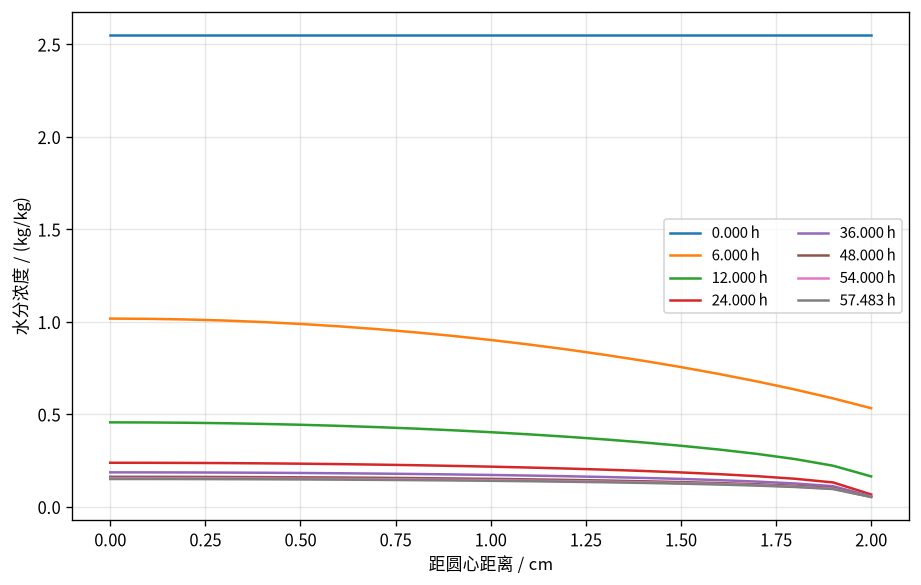

In [15]:

# =========================
# 11. 水分浓度随距离变化图
# =========================
fig, ax = plt.subplots(figsize=(9, 5.5))

for idx, h in zip(profile_indices, profile_hours_actual):
    ax.plot(radius_cm, sol.C[idx, :], label=f"{h:.3f} h")

ax.set_xlabel("距圆心距离 / cm")
ax.set_ylabel("水分浓度 / (kg/kg)")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=9)

保存图片(fig, "图6_典型时刻水分浓度随距离变化图.png")
plt.show()


## 第九部分：热力图 + 临界等值线

对第三问而言，最有解释力的一张图往往是“**水分浓度热力图 + 临界等值线**”。

其中临界等值线对应：

\[
C(r,t) = 0.15
\]

这条曲线可以被理解为“局部达标前沿”。

### 论文写作提示
正文中可以这样解释：

- 等值线外侧区域已经达到要求；
- 等值线向中心逐步推进；
- 最终中心位置最后达到阈值，因此整个样品的干燥完成由中心控制。


已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/图7_水分浓度热力图及临界等值线.png
已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/推荐Fig4_水分浓度热力图及临界等值线.png


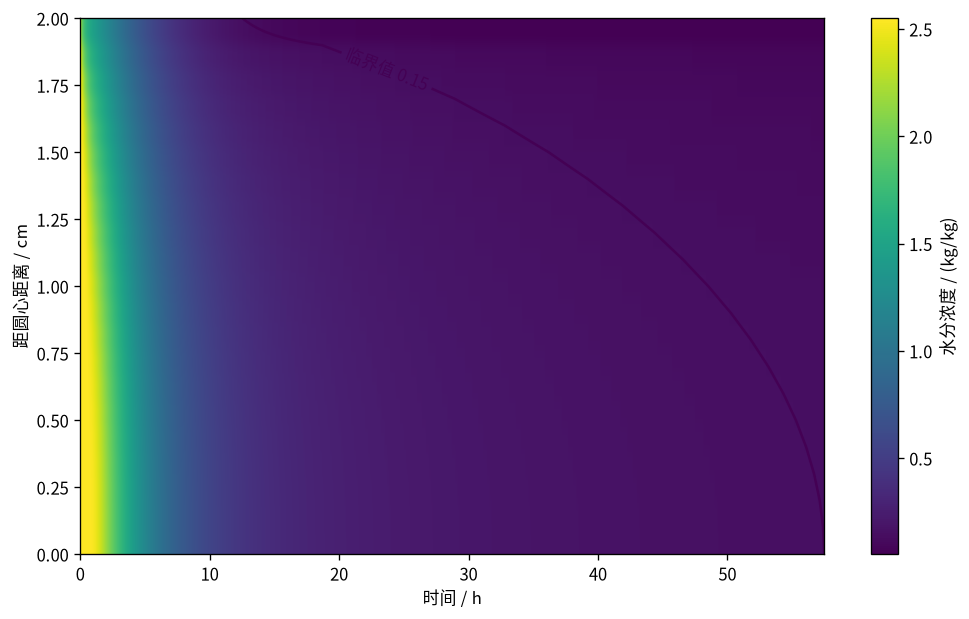

In [16]:

# =========================
# 12. 水分浓度热力图 + 临界等值线
# =========================
X, Y = np.meshgrid(time_h, radius_cm)

fig, ax = plt.subplots(figsize=(10, 5.8))
im = ax.imshow(
    sol.C.T,
    aspect="auto",
    origin="lower",
    extent=[time_h.min(), time_h.max(), radius_cm.min(), radius_cm.max()],
)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("水分浓度 / (kg/kg)")

contour = ax.contour(
    X, Y, sol.C.T,
    levels=[0.15],
)
ax.clabel(contour, fmt={0.15: "临界值 0.15"}, fontsize=10)

ax.set_xlabel("时间 / h")
ax.set_ylabel("距圆心距离 / cm")

保存图片(fig, "图7_水分浓度热力图及临界等值线.png")
保存图片(fig, "推荐Fig4_水分浓度热力图及临界等值线.png")
plt.show()


## 第十部分：最大水分浓度与终止事件图（推荐正文 Fig.5）

第三问最终要求的是：**全域水分浓度都不高于 0.15 时的首次时刻**。  
因而最直接的判据函数是：

\[
g(t)=C_{\max}(t)-0.15
\]

其中 \(C_{\max}(t)\) 表示该时刻样品内部和表面的最大水分浓度。

### 论文写作提示
该图建议作为正文核心结果图之一，用来说明：

- 最大水分浓度随时间单调下降；
- 与阈值 \(0.15\) 的交点即为最终烘干完成时刻；
- 局部放大图可以说明事件定位是稳定且平滑的。


已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/终止事件附近局部轨迹.csv
已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/推荐Fig5_最大水分浓度与终止事件定位.png


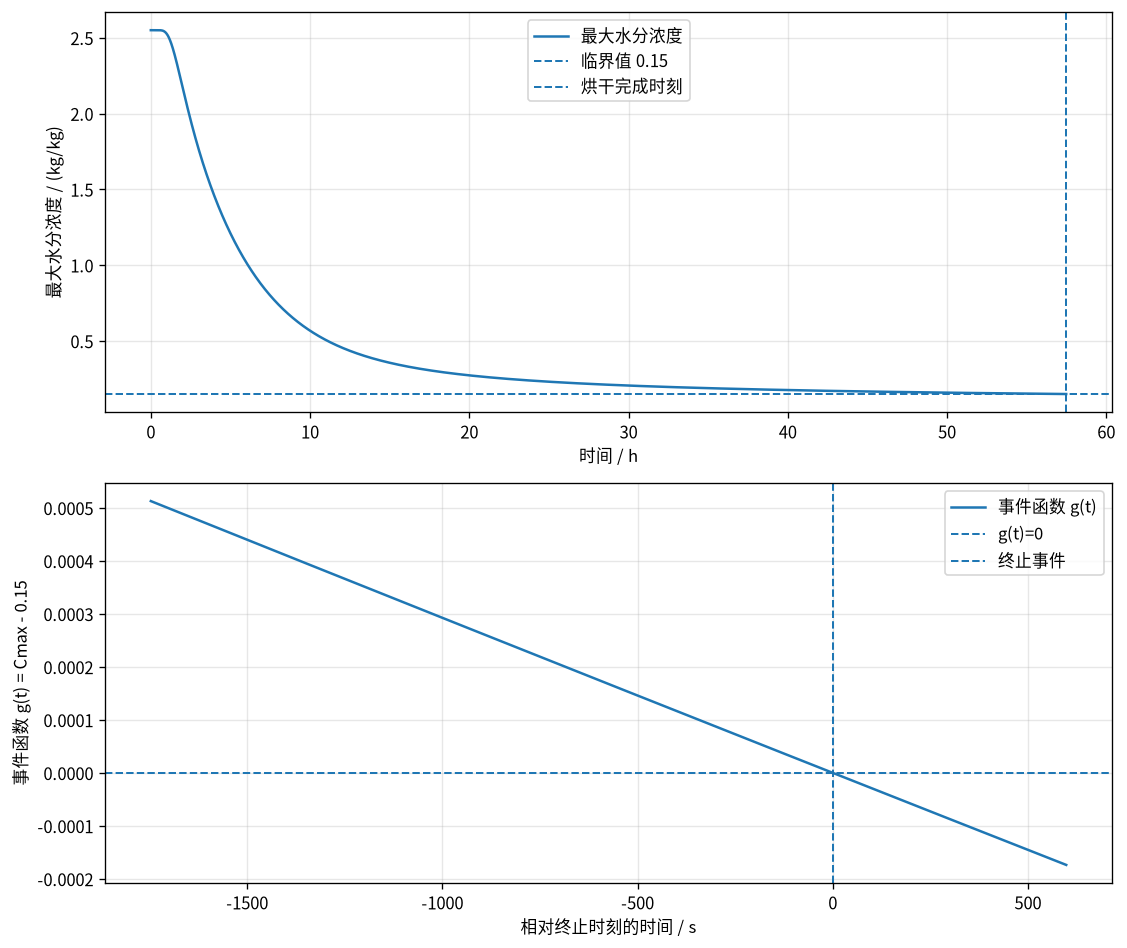

In [17]:

# =========================
# 13. 最大水分浓度与事件函数图
# =========================
# 全过程最大水分浓度（用规则输出近似展示；精确事件时刻由 event 给出）
cmax_curve = sol.C.max(axis=1)

# 事件附近的局部轨迹（更精确）
trace_df = event_local_trace(sol, before_s=600.0, after_s=600.0, dt=5.0)
保存表格(trace_df, "终止事件附近局部轨迹.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(9.5, 8), sharex=False)

# 上图：全程 Cmax
axes[0].plot(sol.t / 3600.0, cmax_curve, label="最大水分浓度")
axes[0].axhline(0.15, linestyle="--", linewidth=1.2, label="临界值 0.15")
axes[0].axvline(sol.t_dry_s / 3600.0, linestyle="--", linewidth=1.2, label="烘干完成时刻")
axes[0].set_xlabel("时间 / h")
axes[0].set_ylabel("最大水分浓度 / (kg/kg)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# 下图：事件附近局部放大
axes[1].plot(trace_df["relative_to_event_s"], trace_df["g"], label="事件函数 g(t)")
axes[1].axhline(0.0, linestyle="--", linewidth=1.2, label="g(t)=0")
axes[1].axvline(0.0, linestyle="--", linewidth=1.2, label="终止事件")
axes[1].set_xlabel("相对终止时刻的时间 / s")
axes[1].set_ylabel("事件函数 g(t) = Cmax - 0.15")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()

保存图片(fig, "推荐Fig5_最大水分浓度与终止事件定位.png")
plt.show()


## 第十一部分：局部达标时间与推荐正文 Fig.6

为了更清楚地说明“为什么最终由中心控制结束”，我们定义每个径向位置的**局部达标时间**：

\[
	au(r)=\inf \{t \mid C(r,t)\le 0.15\}
\]

这张图在高分论文里非常有用，因为它把“观察结论”提升为“定量结论”。

### 论文写作提示
如果这张图单调递减，说明从外到内逐步达标，且：

- 表面最先达到要求；
- 中心最晚达到要求；
- 故全局终止时间由中心位置控制。


已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/局部达标时间_tau_of_r.csv
已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/附图_局部达标时间.png
已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/推荐Fig6_局部达标时间.png


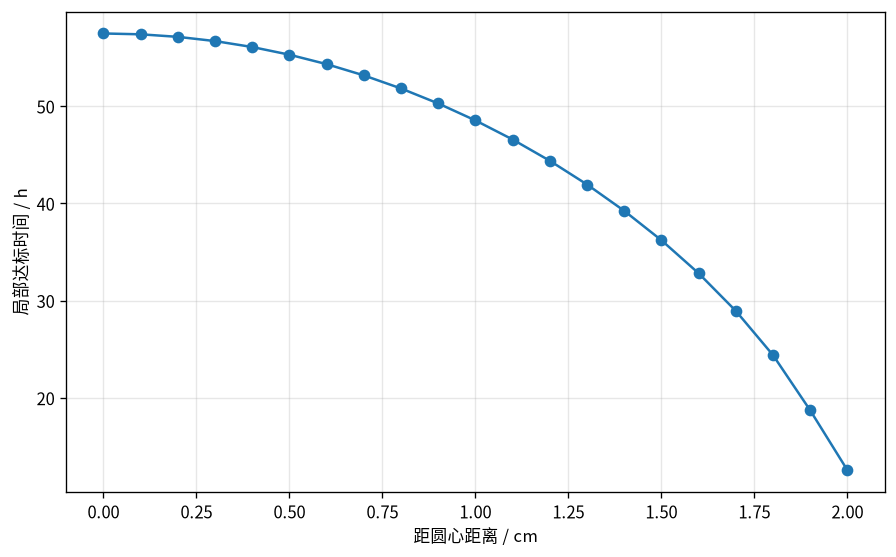

,距圆心距离_cm,局部达标时间_h
0,0.0,57.485253
1,0.1,57.398429
2,0.2,57.137694
3,0.3,56.702194
4,0.4,56.090479


In [18]:

# =========================
# 14. 计算局部达标时间 tau(r)
# =========================
# 将精确事件状态补充到规则输出末端，便于对中心点正确插值
extra_T, extra_C = sample_state_pair(
    sol.T_dry_state,
    sol.C_dry_state,
    sol.t_dry_s,
    sol.r,
    sol.grid,
    sol.env,
    sol.params,
    sol.config.rhs_config(),
)

time_aug = np.concatenate([sol.t, [sol.t_dry_s]])
C_aug = np.vstack([sol.C, extra_C])

tau_h = []
for j in range(C_aug.shape[1]):
    series = C_aug[:, j]
    cross_idx = np.where(series <= 0.15)[0]
    if len(cross_idx) == 0:
        tau_h.append(np.nan)
        continue

    k = int(cross_idx[0])
    if k == 0:
        tau = time_aug[0]
    else:
        t1, t2 = time_aug[k-1], time_aug[k]
        c1, c2 = series[k-1], series[k]
        if abs(c2 - c1) < 1e-14:
            tau = t2
        else:
            tau = t1 + (0.15 - c1) * (t2 - t1) / (c2 - c1)
    tau_h.append(tau / 3600.0)

tau_df = pd.DataFrame({
    "距圆心距离_cm": radius_cm,
    "局部达标时间_h": tau_h,
})
保存表格(tau_df, "局部达标时间_tau_of_r.csv", index=False)

fig, ax = plt.subplots(figsize=(8.8, 5.2))
ax.plot(radius_cm, tau_h, marker="o")
ax.set_xlabel("距圆心距离 / cm")
ax.set_ylabel("局部达标时间 / h")
ax.grid(True, alpha=0.3)

保存图片(fig, "附图_局部达标时间.png")
保存图片(fig, "推荐Fig6_局部达标时间.png")
plt.show()

tau_df.head()


## 第十二部分：补充导出——推荐正文图清单

为方便论文插图整理，下面生成一份图表清单。


In [19]:

# =========================
# 15. 输出文件清单
# =========================
manifest_rows = []

for p in sorted(IMG_DIR.glob("*.png")):
    manifest_rows.append({"类型": "图片", "文件名": p.name, "路径": str(p)})

for p in sorted(TAB_DIR.glob("*")):
    if p.is_file():
        manifest_rows.append({"类型": "表格", "文件名": p.name, "路径": str(p)})

for p in sorted(OUTPUT_DIR.glob("*.xlsx")):
    if p.is_file():
        manifest_rows.append({"类型": "结果文件", "文件名": p.name, "路径": str(p)})

manifest_df = pd.DataFrame(manifest_rows)
保存表格(manifest_df, "输出文件清单_manifest.csv", index=False)

manifest_df

已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/输出文件清单_manifest.csv


,类型,文件名,路径
0,图片,图1_环境温度散点与线性插值.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
1,图片,图2_环境水分浓度散点与线性插值.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
2,图片,图3_温度场时空热力图.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
3,图片,图4_水分浓度场时空热力图.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
4,图片,图5_典型时刻温度随距离变化图.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
5,图片,图6_典型时刻水分浓度随距离变化图.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
6,图片,图7_水分浓度热力图及临界等值线.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
7,图片,推荐Fig1_环境边界条件及长期延拓.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
8,图片,推荐Fig2_温度场时空热力图.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...
9,图片,推荐Fig3_水分浓度场时空热力图.png,/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/M...



## 第十三部分（可选）：高分论文附加分析

以下内容不是本题的最低完成要求，但非常适合在你需要提升论文说服力时使用：

1. **网格收敛分析**：检验 \(N=320, 640, 1280\) 下的终止时间变化；  
2. **长期边界敏感性分析**：比较 `last_hour_mean`、`last_value`、`last_1p5h_mean`；  
3. **终止位置与物理解释**：论证最终由中心位置控制；  
4. **误差预算**：决定结果保留到几位有效数字更合理。

### 论文写作提示
如果你准备冲击高分，这部分分析非常值得做。  
尤其是：

- 网格收敛表 / 图：证明数值结果可信；
- 边界敏感性表：回答“4 h 之后边界如何延拓”这一关键质疑。


已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/网格收敛分析.csv
已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/不同网格下第三问终止时间.csv
已保存图片：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/images/附图_网格收敛分析.png


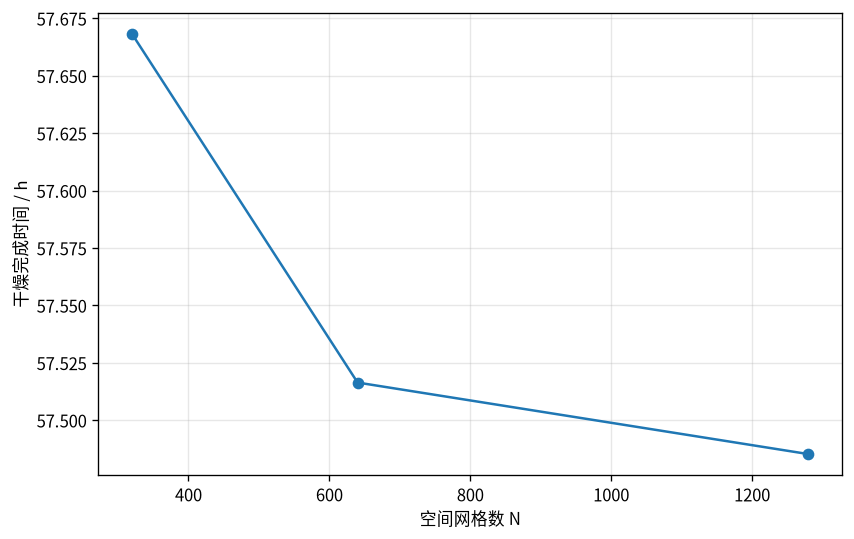

已保存表格：/fs/ess/PAS1475/wangxiaoying/YYhao/Rare_ATAC/MATH_MODEL/Q3_drying_project/Q3_第三问最终竞赛版输出/tables/长期边界敏感性分析.csv


In [21]:

# =========================
# 16. 可选分析开关
# =========================
RUN_OPTIONAL_ANALYSIS = True

if RUN_OPTIONAL_ANALYSIS:
    # ---- (1) 网格收敛分析 ----
    gc_df, gc_results = event_grid_convergence(
        ENV_XLSX,
        N_values=(320, 640, 1280),
        config=q3_config,
        boundary_strategy="last_hour_mean",
    )
    保存表格(gc_df, "网格收敛分析.csv", index=False)

    tdry_rows = []
    for N, res in gc_results.items():
        tdry_rows.append({
            "N": N,
            "干燥完成时间_s": res.t_dry_s,
            "干燥完成时间_h": res.t_dry_h,
            "终止位置_cm": res.rmax_m * 100.0,
        })
    tdry_df = pd.DataFrame(tdry_rows).sort_values("N")
    保存表格(tdry_df, "不同网格下第三问终止时间.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(tdry_df["N"], tdry_df["干燥完成时间_h"], marker="o")
    ax.set_xlabel("空间网格数 N")
    ax.set_ylabel("干燥完成时间 / h")
    ax.grid(True, alpha=0.3)
    保存图片(fig, "附图_网格收敛分析.png")
    plt.show()

    # ---- (2) 长期边界敏感性 ----
    bc_df = boundary_strategy_sensitivity(
        ENV_XLSX,
        N=320,
        config=q3_config,
        strategies=("last_hour_mean", "last_value", "last_1p5h_mean"),
    )
    保存表格(bc_df, "长期边界敏感性分析.csv", index=False)
    bc_df
else:
    print("可选分析未执行。若需要高分论文附加分析，请将 RUN_OPTIONAL_ANALYSIS 改为 True。")


## 最后说明

你现在可以直接使用本 Notebook 做三件事：

1. **正式生成第三问 `result3.xlsx` 与表 5；**  
2. **批量导出论文配图（PNG）；**  
3. **继续扩展高分论文所需的数值验证与敏感性分析。**

如果你下一步愿意，我建议继续做这两件事：

- 我帮你把 **Fig.1 ~ Fig.6 的论文图注和正文解释段落**一起写好；
- 我帮你继续把 **第四问所需图表风格**统一到和第三问一致。

---
**Notebook 输出目录默认位于：**

- 图片：`/mnt/data/Q3_第三问最终竞赛版输出/images/`
- 表格：`/mnt/data/Q3_第三问最终竞赛版输出/tables/`
- 结果文件：`/mnt/data/Q3_第三问最终竞赛版输出/`
